# A10 · 真实CTR：线性与FM交叉的预算对照

先修：公用31–34；A09（19–20章）。

证据类型：**真实采样曝光的训练与select诊断**。本章不声称工业系统复现或线上收益。

学习顺序：先预测 → 只改一个变量 → 运行 → 解释结果。

## 问题与输入输出契约

FM logit=b+Σw_i+Σ_{i<j}<v_i,v_j>；复用推荐课程fm_interaction的向量恒等式，避免复制算法。相同26个类别字段、train-only top64词表、相同训练批次/8 epochs/Adam；唯一结构变量是是否添加4维交互因子，参数量不同明确报告。取原固定Criteo分片前10k真实曝光，不新增数据；仅select开发诊断，不用audit挑模型，不替换正式latest。

运行前预测：本章只改变的变量会使哪一项结果变化？哪些不变量必须保持？

In [1]:
from pathlib import Path
import sys
root=Path.cwd()
if not (root/'reclab').exists(): root=root.parent
if str(root) not in sys.path: sys.path.insert(0,str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab import ads_curriculum as ac

## 运行单变量对照

本章读取已保存的一次真实训练；显式重训见源码函数，避免每次开课自动修改模型。

run 20261030T143314-b0538124


,method,parameters,n,auc,logloss,brier
0,linear,1691,1534,0.607724,0.132267,0.027532
1,fm,8451,1534,0.558951,0.178256,0.031998


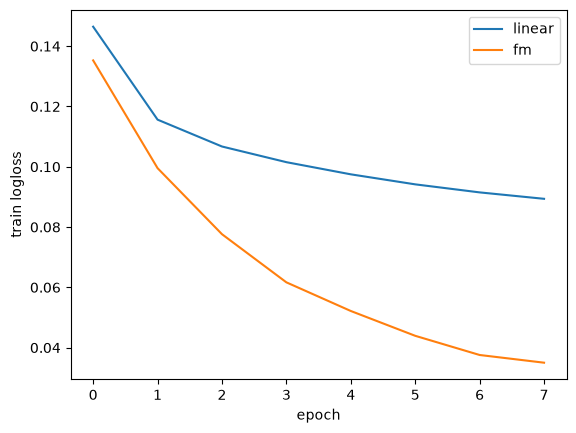

In [2]:
from reclab.paths import ROOT,read_json
summary=read_json(ROOT/'results/2026-10-30-ads-curriculum/fm.json')
print('run',summary['run_id']);display(pd.DataFrame([{'method':r['method'],'parameters':r['parameters'],**{k:r['select'][k] for k in ('n','auc','logloss','brier')}} for r in summary['result']['rows']]))
for row in summary['result']['rows']: plt.plot(row['train_loss'],label=row['method'])
plt.xlabel('epoch');plt.ylabel('train logloss');plt.legend();plt.show()
from reclab.learning.networks import fm_interaction,fm_explicit
import torch
x=torch.randn(3,4,5);assert torch.allclose(fm_interaction(x),fm_explicit(x),atol=1e-5)

## 解释与局限

训练损失下降只说明拟合训练集，select更好也不是正式audit改善。单种子、较小词表、只用类别字段是刻意控制预算的限制。保存结果来自一次实际训练；重训需显式调用ctr_interaction_workshop，新建registry记录并保留负结果。

本次实际输出：线性select logloss=0.1323、FM=0.1783；FM训练loss降得更低而select更差，显示这个小预算配置发生过拟合。保留负结果，不据此否定一般FM或证明真实线上表现。

## 查看源码，再做练习

先预测FM为何可能过拟合；在新的workshop版本只改factor维度并记录参数量，不把改过多次的select当独立测试。

In [3]:
import inspect
print(inspect.getsource(ac.ctr_interaction_workshop))

def ctr_interaction_workshop(rows=10000, epochs=8):
    """Real sampled Criteo categorical LR versus FM; shared recommendation FM operator."""
    import torch
    import time
    from torch import nn
    from .learning.networks import fm_interaction
    from .ads import load_data, split_groups, vocabulary, encode, verify_sources, CAT
    from .probability import evaluate
    from .experiments import begin, finish
    from .paths import ROOT, read_json, atomic_json
    if rows!=10000 or epochs!=8: raise ValueError('Frozen teaching budget: 10k rows, 8 epochs')
    folder=begin('ads',{'workshop':'categorical_fm','rows':rows,'epochs':epochs,'seed':42,'evaluation':'select only'},read_json(ROOT/'docs/ads_sources.json'))
    try:
        verify_sources();frame,_=load_data(rows);masks,_=split_groups(frame)
        vocab=vocabulary(frame.loc[masks['train']],64)
        x=encode(frame,vocab)[:,13:].astype(np.int64)+np.arange(len(CAT))*65
        y=frame.label.to_numpy(dtype=np.float32)
        

## 来源与下一步

A-RTB 39–69页，FM在58页；复用Lab推荐06机制。这是Lab自行设计的小实验，不复制讲义全文。

[GitHub中文单章](https://github.com/SocratesClub/ccrbook/blob/6dbd5650f2adc6e257e5bd5d156bc50a72560ee9/slides/Chapter%208%20%E8%AE%A1%E7%AE%97%E5%B9%BF%E5%91%8A.pptx) · [作者RTB讲义](https://wnzhang.net/slides/cikm-16-rtb-full.pdf)。中文PPT不是现代广告工程全套课；不将历史平台机制描述当作当前市场事实。

完成练习后回到广告学习路径，继续下一语义单元。